# Détection d’activités d’oiseaux dans des enregistrements audio par réseaux de neurones frugaux

Pour utiliser un GPU avec google colab : exécution -> modifier le type d'exécution -> GPU

## 0 - Si besoin : (re-)télécharger les données audio

Soit en les téléchargeant et décompressant depuis les liens suivants :
- examples.zip (4.2 Mo) : https://uncloud.univ-nantes.fr/index.php/s/6XQPXKQ8Syyq3Xb -> pour les deux parties
- dataset.zip (1.1 Go) : https://uncloud.univ-nantes.fr/index.php/s/CEjynZsiXAX8P8g -> pour la seconde partie

Soit en lançant la cellule suivante :


In [1]:
import zipfile, urllib.request

# Tétécharger les fichiers du git (pour les deux parties)
'''
import shutil
from pathlib import Path

# files.zip : https://uncloud.univ-nantes.fr/index.php/s/wyw9sZT3AMD3fCs
url = "https://uncloud.univ-nantes.fr/public.php/dav/files/wyw9sZT3AMD3fCs/?accept=zip"
urllib.request.urlretrieve(url, "files.zip")
with zipfile.ZipFile("files.zip") as z:
    z.extractall("")

for item in Path("files").iterdir():
    shutil.move(str(item), ".")
Path("files").rmdir()
'''

# examples.zip : https://uncloud.univ-nantes.fr/index.php/s/6XQPXKQ8Syyq3Xb -> pour les deux parties
'''
url = "https://uncloud.univ-nantes.fr/public.php/dav/files/6XQPXKQ8Syyq3Xb/?accept=zip"  
urllib.request.urlretrieve(url, "examples.zip")
with zipfile.ZipFile("examples.zip") as z:
    z.extractall("data")
'''

# dataset.zip : https://uncloud.univ-nantes.fr/index.php/s/CEjynZsiXAX8P8g -> pour la partie 2
'''
url = "https://uncloud.univ-nantes.fr/public.php/dav/files/CEjynZsiXAX8P8g/?accept=zip" 
urllib.request.urlretrieve(url, "dataset.zip")
with zipfile.ZipFile("dataset.zip") as z:
    z.extractall("data")
'''


'\nurl = "https://uncloud.univ-nantes.fr/public.php/dav/files/CEjynZsiXAX8P8g/?accept=zip" \nurllib.request.urlretrieve(url, "dataset.zip")\nwith zipfile.ZipFile("dataset.zip") as z:\n    z.extractall("data")\n'

# Partie 2 - Détection par réseaux de neurones

In [2]:
import os
import torch
import torchaudio.transforms as T
import matplotlib.pyplot as plt
import pandas as pd

import librosa
import numpy as np

from src.bcresnet import BCResNets
from src.dataset import Dataset
from src.training import train
from src.utils import plot_mel_spec

In [3]:
df_classes = pd.read_csv("data/classes.csv", sep=";")
n_classes = len(df_classes)
print(df_classes)

       Code          Type             Espece
0  DENMAJ_C           Cri        Pic épeiche
1  DENMAJ_D  Tambourinage        Pic épeiche
2  TURMER_C           Cri         Merle noir
3  TURMER_S         Chant         Merle noir
4  PHYCOL_C           Cri    Pouillot véloce
5  PHYCOL_S         Chant    Pouillot véloce
6  PRUMOD_C           Cri  Accenteur mouchet
7  PRUMOD_S         Chant  Accenteur mouchet


## 2.1 - Initialisation d'un BC-ResNet

In [4]:
bcresnet = BCResNets(base_c=8, 
                     num_classes=n_classes).eval()

In [5]:
# affichage de la liste des couches
print(bcresnet)

BCResNets(
  (input_bn): BatchNorm2d(1, eps=1e-05, momentum=0.01, affine=True, bias=True, track_running_stats=True)
  (cnn_head): Sequential(
    (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(2, 1), padding=(2, 2), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (BCBlocks): ModuleList(
    (0): ModuleList(
      (0): BCResBlock(
        (f2): Sequential(
          (0): ConvBNReLU(
            (block): Sequential(
              (0): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
              (2): ReLU(inplace=True)
            )
          )
          (1): ConvBNReLU(
            (block): Sequential(
              (0): Conv2d(8, 8, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0), groups=8, bias=False)
              (1): SubSpectralNorm(
                (ssnorm): Batc

### Affichage de certains poids du réseau de neurones

In [26]:
# Affichage des poids de la première couche de convolution
print(bcresnet.cnn_head[0].weight)

Parameter containing:
tensor([[[[-0.1346, -0.0676, -0.1412, -0.0133,  0.0517],
          [ 0.1984,  0.0847, -0.1918, -0.0158,  0.1937],
          [ 0.0257, -0.1775,  0.0079,  0.1873, -0.1335],
          [ 0.0299,  0.1888,  0.0354,  0.1451, -0.1958],
          [-0.0972, -0.1811, -0.1341,  0.0431,  0.1159]]],


        [[[-0.1013, -0.1824, -0.0441,  0.1029,  0.1843],
          [ 0.1554, -0.1676, -0.0921,  0.0096, -0.1744],
          [-0.0855,  0.0898,  0.1561,  0.1737,  0.1898],
          [ 0.0173,  0.1130,  0.1780, -0.1337,  0.1410],
          [-0.1451, -0.1472,  0.0682, -0.0410,  0.1421]]],


        [[[-0.1393,  0.0142, -0.0559,  0.1585, -0.1868],
          [ 0.0438,  0.1811,  0.1016, -0.1556,  0.0048],
          [-0.0155, -0.0876,  0.1538, -0.0218, -0.0817],
          [ 0.1905, -0.1640, -0.1542,  0.0442, -0.0372],
          [-0.0661, -0.0118,  0.1831,  0.1012, -0.1504]]],


        [[[ 0.0070, -0.0730, -0.1804, -0.0942, -0.1393],
          [-0.0841, -0.0895, -0.0561,  0.1440,  0.0601

In [27]:
# Affichage des poids de la dernière couche du réseau de neurones
print(bcresnet.classifier[-1].weight)

Parameter containing:
tensor([[[[ 1.1656e-01]],

         [[-1.2334e-01]],

         [[-2.2832e-02]],

         [[ 1.4335e-01]],

         [[ 1.0802e-01]],

         [[ 5.2686e-02]],

         [[-7.0439e-02]],

         [[-7.3631e-02]],

         [[-1.1298e-02]],

         [[ 2.0319e-03]],

         [[ 1.2063e-01]],

         [[-1.6151e-01]],

         [[-1.6704e-01]],

         [[ 1.4220e-01]],

         [[ 1.6012e-02]],

         [[-5.9354e-02]],

         [[ 6.8817e-02]],

         [[ 7.5145e-02]],

         [[ 4.7271e-02]],

         [[-1.0640e-04]],

         [[ 1.6343e-02]],

         [[ 2.8307e-03]],

         [[-4.1815e-02]],

         [[-1.6261e-01]],

         [[ 2.5994e-02]],

         [[-5.0198e-02]],

         [[ 6.6239e-02]],

         [[-2.4318e-02]],

         [[-6.7111e-02]],

         [[-8.1797e-02]],

         [[-1.5328e-01]],

         [[ 1.6138e-01]]],


        [[[-1.4302e-01]],

         [[ 3.8270e-02]],

         [[-3.7894e-02]],

         [[-1.1766e-02]],

    

## 2.3 - Inférence sur un exemple

In [28]:
# chargement d'un clip audio
base_dir = "data/examples"
f_name = "DENMAJ_D_XC704957_t15.wav"
wav_path = os.path.join(base_dir, f_name)

waveform, rate = librosa.load(wav_path, sr=None)

In [29]:
# Définition des paramètres du spectrogramme
n_mels = 40

sample_rate = 24000
f_min_mel = 1000
f_max_mel = 12000

hop_ms = 16
hop_length = int(hop_ms * 24)
win_length = 2 * hop_length
n_fft = 1024

eps = 1e-8
log_transform = lambda x: torch.log1p(x / eps)

spectrogram = T.MelSpectrogram(sample_rate=sample_rate, win_length=win_length, n_fft=n_fft, 
                                            hop_length=hop_length, f_min=f_min_mel, f_max=f_max_mel,
                                            n_mels=n_mels, normalized=False, window_fn=torch.hann_window) 


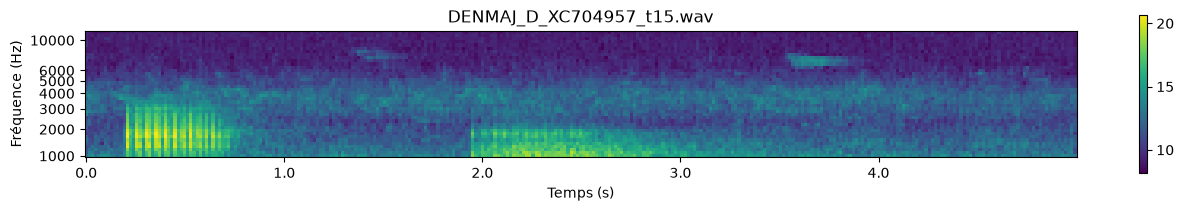

In [30]:
# Calcul et affichage du spectrogramme
mel_spec = spectrogram(torch.tensor(waveform))
log_mel_spec = log_transform(mel_spec)

plot_mel_spec(log_mel_spec, f_min_mel, f_max_mel, n_mels, 
            hop_length, waveform.shape[-1], sample_rate,
            title=f_name)

log_mel_spec = log_mel_spec.reshape(1, 1, *log_mel_spec.shape)

### Logits et scores de confiance

On obtient la sortie du réseau de neurones avec ```bcresnet(log_mel_spec)```
Cette sortie est un vecteur de nombres réels quelconques appelés *logits*.
Ils peuvent être convertis en des scores de confiance compris entre 0 et 1 en appliquant le fonction sigmoïde :
$\sigma(z) = \frac{1}{1 + e^{-z}}$
implémentée en pyTorch sous ```torch.sigmoid```

In [ ]:
logits = ...
confidence_scores = ...

print("Logits :")
print(logits.detach().numpy())
print("Scores de confiance :")
print(confidence_scores.detach().numpy())

Logits :
[[ 0.12078114 -0.10889276  0.09112027 -0.02028915 -0.07944302  0.15916201
   0.0462211  -0.13660306]]
Scores de confiance :
[[0.53015864 0.47280368 0.5227643  0.49492788 0.48014966 0.5397067
  0.5115532  0.46590224]]


## 2.4 - Utilisation d'un dataset

In [12]:
train_folder = "data/dataset/train/files"
eval_folder = "data/dataset/eval/files"

train_set = Dataset(train_folder, df_classes)
eval_set = Dataset(eval_folder, df_classes)

In [18]:
waveform, label = train_set[0]
print(f"Taille de la forme d'onde : {waveform.shape}")
print(f"Label: {label}")

Taille de la forme d'onde : (120000,)
Label: [0. 0. 0. 0. 0. 0. 0. 1.]


In [ ]:
print("Nombre de clips positifs par classe :")
print(train_set.labels.sum(0))

neg_files = (train_set.labels.max(1) == 0).sum()
print("Nombre de clips négatifs :")
print(neg_files)

Nombre de clips positifs par classe :
[162. 196. 151. 335. 163. 240. 135. 197.]
Nombre de clips négatifs :
414


## 2.5 - Apprentissage du réseau de neurones

Cette partie est lourde en calcul et peut être passée.
La partie suivante fournit directement un réseau de neurones entraîné.

In [ ]:
# Paramètres d'apprentissage
batch_size = 32
n_epochs = 2
lr = 1e-3

tau = 2 # Taille du réseau de neurones

# Utilisation de CPU ou GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
#device = "mps:0"

seed = 0

torch.manual_seed(seed)
bcresnet = BCResNets(base_c=int(8*tau), 
                     num_classes=n_classes)

hist = train(bcresnet, spectrogram, log_transform, 
          lr, n_epochs, batch_size,
          train_set, eval_set, n_classes, 
          device)

train_loss_hist, train_f1_hist, eval_loss_hist, eval_f1_hist = hist
train_f1_hist = torch.vstack(train_f1_hist).cpu().numpy()
eval_f1_hist = torch.vstack(eval_f1_hist).cpu().numpy()

Epoch 01/30 | train loss 0.4759 | test loss 0.3770 | test F1 moyen 0.040
  F1 par classe (test) : 0.00 0.00 0.00 0.32 0.00 0.00 0.00 0.00
Epoch 02/30 | train loss 0.2808 | test loss 0.2968 | test F1 moyen 0.088
  F1 par classe (test) : 0.00 0.00 0.00 0.47 0.00 0.24 0.00 0.00
Epoch 03/30 | train loss 0.2343 | test loss 0.2253 | test F1 moyen 0.213
  F1 par classe (test) : 0.00 0.00 0.00 0.66 0.00 0.54 0.00 0.51
Epoch 04/30 | train loss 0.2044 | test loss 0.1969 | test F1 moyen 0.292
  F1 par classe (test) : 0.04 0.00 0.00 0.72 0.00 0.64 0.06 0.87
Epoch 05/30 | train loss 0.1817 | test loss 0.1888 | test F1 moyen 0.312
  F1 par classe (test) : 0.12 0.00 0.00 0.74 0.00 0.58 0.18 0.87
Epoch 06/30 | train loss 0.1577 | test loss 0.1716 | test F1 moyen 0.398
  F1 par classe (test) : 0.29 0.00 0.20 0.78 0.11 0.57 0.38 0.87
Epoch 07/30 | train loss 0.1366 | test loss 0.1567 | test F1 moyen 0.552
  F1 par classe (test) : 0.67 0.49 0.00 0.81 0.50 0.62 0.43 0.91
Epoch 08/30 | train loss 0.1177 | 

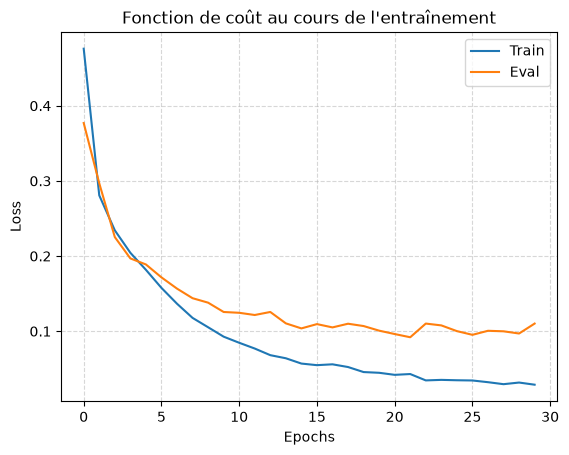

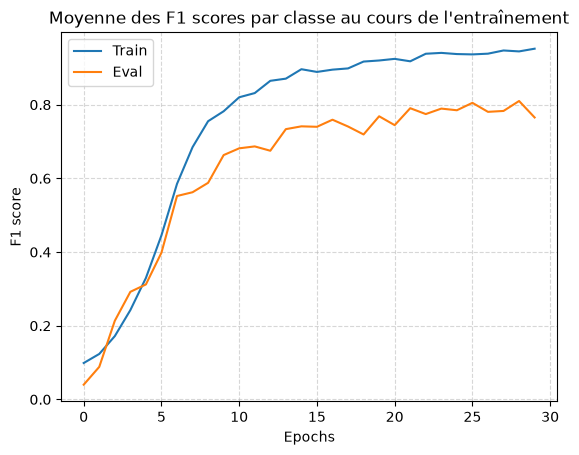

In [46]:
plt.plot(train_loss_hist, label="Train")
plt.plot(eval_loss_hist, label="Eval")
plt.legend()
plt.grid(linestyle="--", alpha=0.5)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Fonction de coût au cours de l'entraînement")
plt.show()

plt.plot(train_f1_hist.mean(1), label="Train")
plt.plot(eval_f1_hist.mean(1), label="Eval")
plt.legend()
plt.grid(linestyle="--", alpha=0.5)
plt.xlabel("Epochs")
plt.ylabel("F1 score")
plt.title("Moyenne des F1 scores par classe au cours de l'entraînement")
plt.show()


In [ ]:
# Sauvegarde du réseau entraîné
# torch.save(bcresnet, "trained_bcresnet")

## 2.6 - Test sur quelques exemples

In [ ]:
# Chargement du réseau de neurones entraîné
loaded_model = torch.load("trained_bcresnet", weights_only=False).to("cpu").eval()
spectrogram.to("cpu")

MelSpectrogram(
  (spectrogram): Spectrogram()
  (mel_scale): MelScale()
)

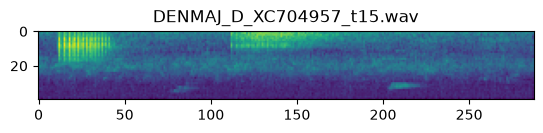

Détections:
- Tambourinage de Pic épeiche (DENMAJ_D)	Confiance: 92.24 %



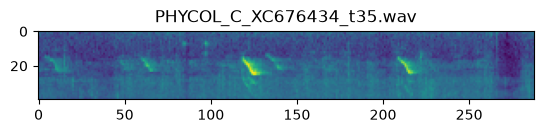

Détections:
- Cri de Pouillot véloce (PHYCOL_C)	Confiance: 99.99 %



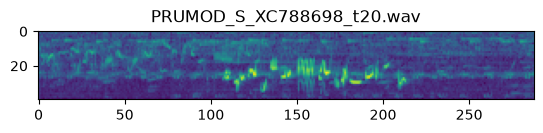

Détections:
- Chant de Accenteur mouchet (PRUMOD_S)	Confiance: 99.85 %



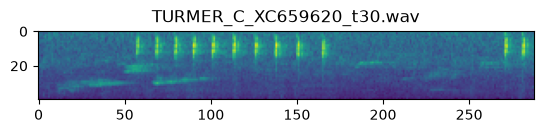

Détections:
- Cri de Merle noir (TURMER_C)	Confiance: 99.83 %



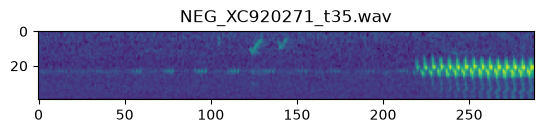

Détections:
Aucune



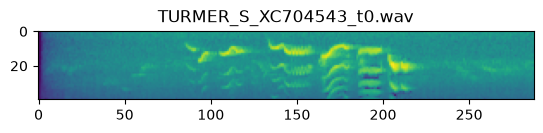

Détections:
- Chant de Merle noir (TURMER_S)	Confiance: 99.91 %



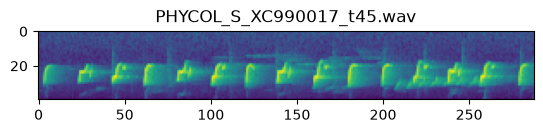

Détections:
- Chant de Pouillot véloce (PHYCOL_S)	Confiance: 100.00 %



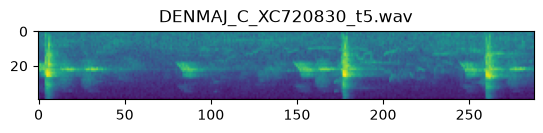

Détections:
- Cri de Pic épeiche (DENMAJ_C)	Confiance: 95.68 %



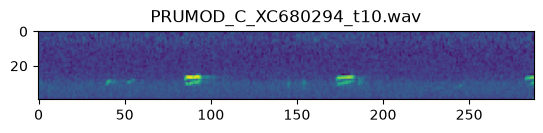

Détections:
- Cri de Accenteur mouchet (PRUMOD_C)	Confiance: 96.17 %



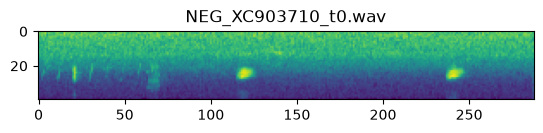

Détections:
- Cri de Accenteur mouchet (PRUMOD_C)	Confiance: 66.06 %



In [ ]:
threshold = 0.5

examples_folder = "data/examples"
f_names = os.listdir(examples_folder)

for f_name in f_names:
    # Chargement de chaque fichier audio
    wav_path = os.path.join(examples_folder, f_name)
    waveform, rate = librosa.load(wav_path)
    waveform = torch.tensor(waveform)

    # Calcul du spectrogramme
    log_mel_spec = ...

    plt.imshow(log_mel_spec, origin="lower")
    plt.title(f_name)
    plt.show()

    log_mel_spec = log_mel_spec.reshape(1, 1, *log_mel_spec.shape)

    # Compléter pour calculer les sorties du réseau de neurones
    logits = ...
    scores = ...

    # Tri par score décroissant
    scores = scores[0].detach()
    idx = torch.argsort(scores, descending=True).numpy()

    print("Détections:")
    if max(scores) < threshold:
        print("Aucune")

    for i in idx:
        # Compléter avec une condition de détection sur scores[i]
        if ... :
            detected_class = df_classes.loc[i]
            print(f"- {detected_class["Type"]} de {detected_class["Espece"]} ({detected_class["Code"]})", end="\t")
            print(f"Confiance: {float(scores[i])*100:.2f} %")

    print()